# Chambolle-Pock for Color Denoising in 3D point clouds

In this notebook, we demonstrate an extension of the Chambolle-Pock method to a new application: color denoising in 3D point cloud representations. 

The Chambolle-Pock method [1]  is a first-order method for convex imaging problems. The authors show how the method can be applied in a variety of settings, including denoising of 2D gray images formulated as the Rudin-Osher-Fatemi (ROF) model.

We desire to extend this method to color denoising in 3D point clouds. Often, point clouds are obtained from 3D scans of real-world objects, and they may contain noise in the form of color speckles. Can we use the Chambolle-Pock method to denoise the color of a point cloud extending the ROF model to 3D?

Particularly, we consider the following problem:
- Start from the ROF model that Chambolle and Pock solve on a 2D gray image.
- Extend it to model 3D point clouds.
- Use the Chambolle-Pock method to denoise the color of a point cloud.
- Analyze the solution for quality of denoising and the effect of different parameters.


## Problem setup

We consider the infamous cow Spot, a public-domain model from Keenan Crane. (https://www.cs.cmu.edu/~kmcrane/Projects/ModelRepository/spot.zip).

We sample 8000 points out of 161,985 points uniformly by area on the surface and read the texture color at each point. Gaussian noise of standard deviation 0.35 is added to each color channel and the result is clipped to $[0, 1]$. 


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


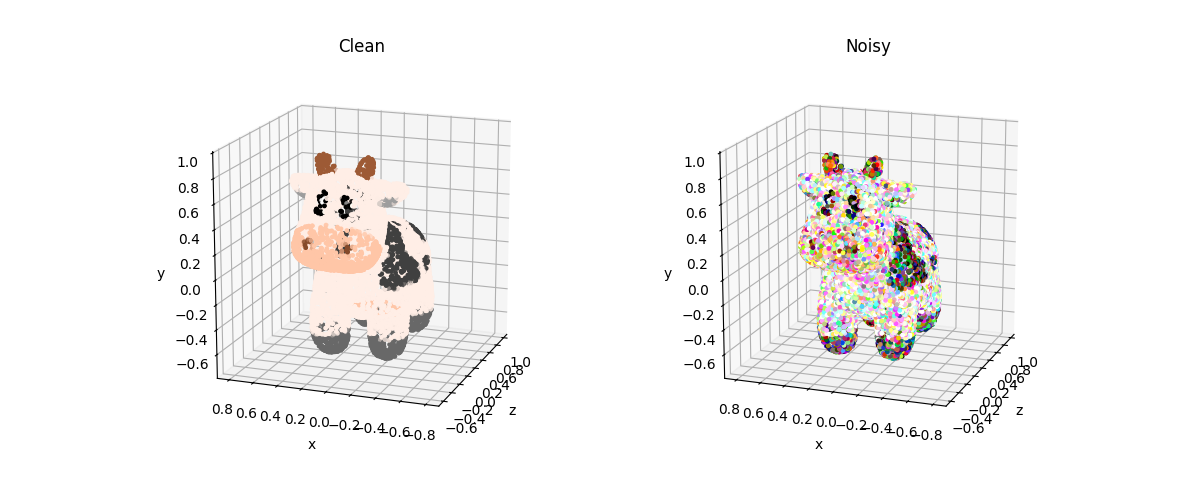

In [6]:
# Here, the model is located in the `models/experiments/exp_color/spot.zip` file, including the mesh 'triangulated.obj' and the texture 'spot_texture.png'.

%matplotlib widget
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd()
if not (ROOT / "experiments" / "exp_color").exists():
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT / "src"), str(ROOT)]

from experiments.exp_color.color import add_color_noise, color_mse, denoise_color
from experiments.exp_color.figure import DIAGONAL_VERTICAL, draw_colored_cloud
from experiments.exp_color.mesh import read_obj_triangles, read_texture, sample_textured_mesh
from experiments.exp_color.run_exp_color import _spot_paths

N_POINTS = 8000
NEIGHBORS = 8
NOISE_STD = 0.35
SEED = 0

obj_path, texture_path = _spot_paths()
vertices, uvs, vertex_ids, uv_ids = read_obj_triangles(obj_path)
texture = read_texture(texture_path)
rng = np.random.default_rng(SEED)
points, clean = sample_textured_mesh(
    vertices, uvs, vertex_ids, uv_ids, texture, N_POINTS, rng
)
noisy = add_color_noise(clean, NOISE_STD, rng)

# Plot both the clean and noisy point clouds
figure = plt.figure(figsize=(12, 5))
clean_axis = figure.add_subplot(121, projection="3d")
noisy_axis = figure.add_subplot(122, projection="3d")
draw_colored_cloud(clean_axis, points, clean, "Clean")
draw_colored_cloud(noisy_axis, points, noisy, "Noisy")
plt.show()


## The Total Variation Problem on a 2D Image

On a gray image, Chambolle and Pock solve the Rudin–Osher–Fatemi (ROF) problem

$$
\min_u \frac{\lambda}{2}\|u - g\|_2^2 + \|\nabla u\|_1 .
$$

where  $g$ is the noisy image and $u$ is the image we want to recover and $\lambda$ is a parameter that controls the trade-off between the data term and the regularization term. 

1. The Total Variation (TV) Regularizer:
The term $\|\nabla u\|_1$ is the isotropic total variation of the image $u$. It measures the "roughness" of the image by summing the Euclidean length of the gradients between neighboring pixels. Minimizing this term encourages piecewise smooth regions and preserves edges. Unlike the L2 norm, the TV norm is not differentiable at the discontinuities, which makes it more suitable for preserving edges while removing noise.

2. The Data Preservation Term:
The term $\frac{1}{2}\|u - g\|_2^2$ is a quadratic data term that measures the difference between the denoised image $u$ and the noisy image $g$. Minimizing this term ensures that the denoised image is close to the noisy image.

The parameter $\lambda$ controls the trade-off between data fidelity and smoothness. A larger $\lambda$ results in a denoised image closer to the noisy image while a smaller $\lambda$ emphasizes the smoothness of the denoised image.


## From a pixel grid to a point cloud

A 2D image with a matrix of pixels contains an implicit ordering of left-to-right and top-to-bottom. Thereby, the gradient operator is well defined. In contrast, a point cloud is a collection of points without any order. 

Inspired from [2], we represent the point cloud as a symmetric undirected graph where each point is a vertex connected to its $k$ nearest neighbors by weighted edges.

Following standard practice, we define the gradient operator on the point cloud as the weighted difference between the values of neighboring points:
$$
(\nabla u)_{ij} = \sqrt{w_{ij}}\,(u_j - u_i).
$$
where $w_{ij}$ is the weight on the edge between points $i$ and $j$. 

The weight can encode the distance between the points, the feature similarity, or other pairwise relationships.

The TV regularization then becomes:
$$
\mathrm{TV}(u) = \sum_i \left( \sum_{j \sim i} (u_j - u_i)^2 \right)^{1/2}.
$$

and the ROF problem on the point cloud becomes:
$$
\min_u \frac{\lambda}{2}\sum_{i=1}^{N} (u_i - g_i)^2 + \mathrm{TV}(u).
$$

For color denoising, we solve the problem separately for each color channel.

The model code is written in `src/cp_pointcloud/denoise.py`.


## The Chambolle–Pock Iteration

Chambolle and Pock [1] write the ROF problem as $\min_x F(Kx) + G(x)$. Here, $K$ is the gradient, $G$ is the quadratic data term, and $F$ is the norm inside the total variation.

$F$ and $G$ may be non-smooth but their proximal operators are easy to compute.

We take a primal variable $x$, a dual variable $y$, and an extrapolated primal variable $\bar{x}$. We set $\bar{x}^0 = x^0$. Each iteration then does three updates, and we keep $\theta = 1$.

The dual step reads $\bar{x}$, the value extrapolated at the previous iteration:

$$
y^{n+1} = \operatorname{prox}_{\sigma F^*}\bigl(y^n + \sigma K \bar{x}^n\bigr).
$$

The proximal map is the map of the conjugate $F^*$. For the total variation this is the projection onto the unit ball.

The primal step then updates $x$ with the new dual variable:

$$
x^{n+1} = \operatorname{prox}_{\tau G}\bigl(x^n - \tau K^* y^{n+1}\bigr).
$$

The extrapolation is on $x$. It builds the $\bar{x}$ that the next dual step will read:

$$
\bar{x}^{n+1} = x^{n+1} + \theta \,(x^{n+1} - x^n).
$$

With $\theta = 1$ this is $\bar{x}^{n+1} = 2x^{n+1} - x^n$. The step sizes satisfy $\tau \sigma \|K\|^2 < 1$. We stop when the relative change of $x$ falls below $10^{-5}$, or after 5000 iterations.

The iteration is implemented in  `chambolle_pock` in `src/cp_pointcloud/denoise.py`. We call it from `denoise_color` in `experiments/exp_color/color.py`, after `knn_graph` has built the edges from the positions.


## Color denoising on 3D Point Clouds

We demonstrate the method on the cow Spot and measure the mean square error against the clean texture sample, at the same point index:

$$
\mathrm{MSE} = \frac{1}{3N}\sum_{i=1}^{N}\sum_{c=1}^{3}\bigl(u_{i,c} - u^{\mathrm{clean}}_{i,c}\bigr)^{2}.
$$

Large values of  $\lambda$ shows little denoising while smaller values oversmoothens the coat.

Below we show an interactive plot showing the denoising results across various values of the parameters.


In [7]:
import ipywidgets as widgets
from IPython.display import display

with plt.ioff():
    comparison = plt.figure(figsize=(12, 4.6))
axis_clean = comparison.add_subplot(1, 3, 1, projection="3d")
axis_noisy = comparison.add_subplot(1, 3, 2, projection="3d")
axis_restored = comparison.add_subplot(1, 3, 3, projection="3d")
comparison.subplots_adjust(top=0.84, wspace=0.12)
draw_colored_cloud(axis_clean, points, clean, "Clean")
draw_colored_cloud(axis_noisy, points, noisy, "Noisy")

color_cache = {}
caption = widgets.HTML(layout=widgets.Layout(width="100%"))
lam_slider = widgets.FloatLogSlider(
    value=12.0,
    base=10,
    min=-0.3,
    max=2.3,
    step=0.05,
    description="λ",
    continuous_update=False,
    readout_format=".3g",
    layout=widgets.Layout(width="420px"),
    style={"description_width": "16px"},
)


def mse_caption(restored):
    return (
        "<div style='text-align:center; font-size:14px; color:#333; padding-top:4px;'>"
        f"MSE &nbsp; clean {color_mse(clean, clean):.3e}"
        f" &nbsp;&middot;&nbsp; noisy {color_mse(noisy, clean):.3e}"
        f" &nbsp;&middot;&nbsp; restored {color_mse(restored, clean):.3e}"
        "</div>"
    )


def show_lambda(lam, keep_view):
    lam = float(lam)
    if lam not in color_cache:
        color_cache[lam] = denoise_color(points, noisy, k=NEIGHBORS, lam=lam)
    restored = color_cache[lam]
    if keep_view:
        elev, azim = axis_restored.elev, axis_restored.azim
    axis_restored.cla()
    draw_colored_cloud(axis_restored, points, restored, "Restored")
    if keep_view:
        axis_restored.view_init(elev=elev, azim=azim, vertical_axis=DIAGONAL_VERTICAL)
    comparison.suptitle(rf"$\lambda = {lam:.3g}$", fontsize=14)
    comparison.canvas.draw_idle()
    caption.value = mse_caption(restored)


def on_slider(change):
    show_lambda(change["new"], keep_view=True)


lam_slider.observe(on_slider, names="value")
show_lambda(lam_slider.value, keep_view=False)
controls = widgets.HBox(
    [lam_slider],
    layout=widgets.Layout(width="100%", justify_content="center", padding="0 0 6px 0"),
)
display(
    widgets.VBox(
        [controls, comparison.canvas, caption],
        layout=widgets.Layout(align_items="center", width="100%"),
    )
)


## Effect of various parameters

The plot above changes $\lambda$ on a graph with a given nearest neighbor count $k$ and every edge weight equal ($=1$). Here, we attempt to analyze the effects of these parameters, ie, the choice of graph representation.

$k$ is the number of neighbors of each point. A larger value can smoothen out over a larger area. While a smaller value can preserve the details.

The weight is either equal or based on distance to neighbors. Equal sets $w_{ij} = 1$, so every neighbor pulls the same amount. Distance sets

$$
w_{ij} = \exp\left(-\frac{\|x_i - x_j\|^2}{h^2}\right),
$$

where $h$ is the median length of the edges in the current graph. The total variation uses that weight,

$$
\mathrm{TV}(u) = \sum_i \left( \sum_{j \sim i} w_{ij}(u_j - u_i)^2 \right)^{1/2}.
$$

A close neighbor must agree. A far neighbor may keep a different color. $\lambda$ is the weight on the noisy color. The step sizes are computed from the graph, so a heavier neighborhood takes smaller steps of the same iteration.


In [5]:
import ipywidgets as widgets
from IPython.display import display

with plt.ioff():
    parameter_figure = plt.figure(figsize=(12, 4.6))
parameter_clean = parameter_figure.add_subplot(1, 3, 1, projection="3d")
parameter_noisy = parameter_figure.add_subplot(1, 3, 2, projection="3d")
parameter_restored = parameter_figure.add_subplot(1, 3, 3, projection="3d")
parameter_figure.subplots_adjust(top=0.84, wspace=0.12)
draw_colored_cloud(parameter_clean, points, clean, "Clean")
draw_colored_cloud(parameter_noisy, points, noisy, "Noisy")

parameter_cache = {}
parameter_seen = {"view": False}
caption = widgets.HTML(layout=widgets.Layout(width="100%"))
control_layout = widgets.Layout(width="230px", margin="0 8px")
control_style = {"description_width": "52px"}
k_slider = widgets.IntSlider(
    value=NEIGHBORS,
    min=1,
    max=32,
    step=1,
    description="k",
    continuous_update=False,
    layout=control_layout,
    style=control_style,
)
weight_choice = widgets.Dropdown(
    options=[("equal", "equal"), ("distance", "distance")],
    value="equal",
    description="weight",
    layout=control_layout,
    style=control_style,
)
parameter_lam = widgets.FloatLogSlider(
    value=12.0,
    base=10,
    min=-0.3,
    max=2.3,
    step=0.05,
    description="λ",
    continuous_update=False,
    readout_format=".3g",
    layout=control_layout,
    style=control_style,
)


def mse_caption(restored):
    return (
        "<div style='text-align:center; font-size:14px; color:#333; padding-top:4px;'>"
        f"MSE &nbsp; clean {color_mse(clean, clean):.3e}"
        f" &nbsp;&middot;&nbsp; noisy {color_mse(noisy, clean):.3e}"
        f" &nbsp;&middot;&nbsp; restored {color_mse(restored, clean):.3e}"
        "</div>"
    )


def show_parameters(_change=None):
    k = int(k_slider.value)
    weight = weight_choice.value
    lam = float(parameter_lam.value)
    key = (k, weight, lam)
    if key not in parameter_cache:
        parameter_cache[key] = denoise_color(points, noisy, k=k, lam=lam, weight=weight)
    restored = parameter_cache[key]
    keep_view = parameter_seen["view"]
    if keep_view:
        elev, azim = parameter_restored.elev, parameter_restored.azim
    parameter_restored.cla()
    draw_colored_cloud(parameter_restored, points, restored, "Restored")
    if keep_view:
        parameter_restored.view_init(elev=elev, azim=azim, vertical_axis=DIAGONAL_VERTICAL)
    parameter_seen["view"] = True
    parameter_figure.suptitle(
        rf"$k = {k}$, {weight} weight, $\lambda = {lam:.3g}$",
        fontsize=14,
    )
    parameter_figure.canvas.draw_idle()
    caption.value = mse_caption(restored)


k_slider.observe(show_parameters, names="value")
weight_choice.observe(show_parameters, names="value")
parameter_lam.observe(show_parameters, names="value")
show_parameters()
controls = widgets.HBox(
    [k_slider, weight_choice, parameter_lam],
    layout=widgets.Layout(
        width="100%",
        justify_content="center",
        align_items="center",
        padding="0 0 6px 0",
    ),
)
display(
    widgets.VBox(
        [controls, parameter_figure.canvas, caption],
        layout=widgets.Layout(align_items="center", width="100%"),
    )
)


## Conclusion

We started from the ROF problem in Chambolle and Pock, and demonstrated an extension of the method to 3D Point Cloud denoising.


## References

[1] Chambolle and T. Pock, A first-order primal-dual algorithm for convex problems with applications to imaging, Journal of Mathematical Imaging and Vision 40 (2011), 120–145.

[2] D. Tenbrinck, F. Lozes, and A. Elmoataz, Solving minimal surface problems on surfaces and point clouds, Scale Space and Variational Methods in Computer Vision (2015).